# [drosophila_body_orientation_predictor](https://github.com/nehalsinghmangat/drosophila_body_orientation_predictor) — Full vs. high-confidence training data

Compares the ANN trained on all training frames (`02_training_and_testing_the_ann.ipynb`) with the same ANN trained only on frames with `heading_confidence > 0.99` (`06_training_high_confidence_ann.ipynb`). Both were trained five times (seeds 42, 7, 13, 99, 123) on the same training trajectories and are scored on the same held-out trajectories, on two sets of held-out frames: **all frames**, and only the **confident frames** (`heading_confidence > 0.99`), where the ground-truth heading is most trustworthy.

Run after notebook 06; it reads `../tables/ann_conf0.99_test_frame_errors.csv` (one row per held-out frame, with the angular error of each of the ten models).

The seeds matter here: the five high-confidence models differ much more from each other than the five full-data models do, and the seed-42 high-confidence model is the best of its five. So every comparison below pools the seeds rather than comparing the two seed-42 models:

1. **Error by regime**: each seed's median per-trajectory error, overall and per regime.
2. **Error distribution**: the distribution of per-trajectory errors (averaged over the five seeds).
3. **Error vs. heading confidence**: frame error in bins of the held-out frames' own heading confidence.
4. **Paired difference**: per held-out trajectory, full-data error minus high-confidence error (each averaged over the five seeds), with a bootstrap CI and a Wilcoxon signed-rank test.

Error is the median per-trajectory angular error (deg), as in notebook 02, unless stated otherwise.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator
from scipy.stats import wilcoxon
from IPython.display import display

CONF_THRESHOLD = 0.99
SEEDS = [42, 7, 13, 99, 123]
REGIMES = ['upwind', 'crosswind', 'downwind']
GROUPS = ['overall'] + REGIMES
os.makedirs('../figures', exist_ok=True)

frames = pd.read_csv(f'../tables/ann_conf{CONF_THRESHOLD}_test_frame_errors.csv')
confident = frames['heading_confidence'] > CONF_THRESHOLD
EVAL_SETS = {'All held-out frames': frames, f'Held-out frames with confidence > {CONF_THRESHOLD}': frames[confident]}
MODELS = {'full': 'All training frames', 'conf': f'Training frames with confidence > {CONF_THRESHOLD}'}
COLORS = {'full': '#2a78d6', 'conf': '#eb6834'}   # categorical slots 1 and 2 of the reference palette
INK, MUTED = '#0b0b0b', '#52514e'
print(f'{len(frames)} held-out frames, {frames["trajec_objid"].nunique()} trajectories; '
      f'{confident.sum()} confident frames in {frames.loc[confident, "trajec_objid"].nunique()} trajectories')


def per_traj(f, col, group):
    '''median error per trajectory, over all its frames (overall) or its frames in one regime'''
    g = f if group == 'overall' else f[f['regime'] == group]
    return g.groupby('trajec_objid')[col].median()


def seed_mean_per_traj(f, model, group):
    '''per-trajectory error averaged over the five seeds of one training recipe'''
    return pd.concat([per_traj(f, f'err_{model}_s{s}', group) for s in SEEDS], axis=1).mean(axis=1)


def bootstrap_ci(values, n_boot=5000, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boot_medians = np.median(rng.choice(values, size=(n_boot, len(values)), replace=True), axis=1)
    lo, hi = np.percentile(boot_medians, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return float(np.median(values)), float(lo), float(hi)


def style(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK)
    ax.grid(axis='y', color='#e4e3df', lw=0.6, which='major'); ax.set_axisbelow(True)


def log_ticks(ax, ticks, axis='y'):
    a = ax.yaxis if axis == 'y' else ax.xaxis
    a.set_major_locator(FixedLocator(ticks)); a.set_minor_locator(NullLocator())
    (ax.set_yticklabels if axis == 'y' else ax.set_xticklabels)([f'{t:g}' for t in ticks])

36942 held-out frames, 1096 trajectories; 30170 confident frames in 957 trajectories


## 1. Error by regime, per seed

Each dot is one trained model's median per-trajectory error; the horizontal bar is the mean over its five seeds. Left: scored on all frames of the held-out trajectories; right: only on their confident frames (trajectories without a confident frame, or without one in a regime, drop out; `n` gives the number of trajectories). Log scale, because the crosswind error is several times the others.

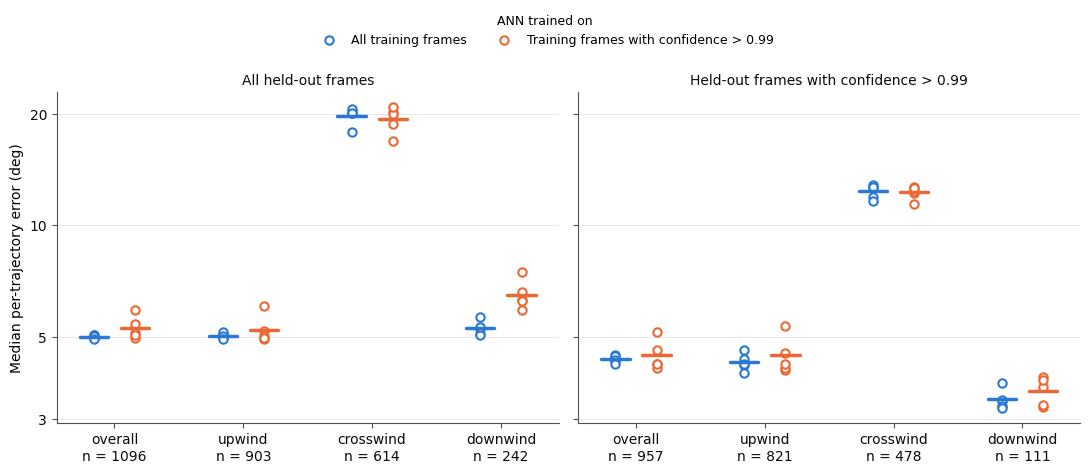

Median per-trajectory error (deg), mean ± sd over the five seeds


All training frames  \
eval_set                               group                           
All held-out frames                    overall           5.00 ± 0.05   
                                       upwind            5.02 ± 0.09   
                                       crosswind        19.79 ± 1.11   
                                       downwind          5.26 ± 0.24   
Held-out frames with confidence > 0.99 overall           4.34 ± 0.10   
                                       upwind            4.26 ± 0.22   
                                       crosswind        12.35 ± 0.52   
                                       downwind          3.38 ± 0.21   

                                                 Training frames with confidence > 0.99  
eval_set                               group                                             
All held-out frames                    overall                              5.28 ± 0.38  
                                       upwind                               5.22 ± 0.47  
                                       crosswind                           19.36 ± 1.55  
                                       downwind                             6.50 ± 0.59  
Held-out frames with confidence > 0.99 overall                              4.46 ± 0.43  
                                       upwind                               4.45 ± 0.53  
                                       crosswind                           12.27 ± 0.52  
                                       downwind                             3.57 ± 0.31

In [2]:
rows = []
for eval_set, f in EVAL_SETS.items():
    for model in MODELS:
        for seed in SEEDS:
            for group in GROUPS:
                v = per_traj(f, f'err_{model}_s{seed}', group)
                rows.append({'eval_set': eval_set, 'model': model, 'seed': seed, 'group': group, 'n': len(v), 'median': v.median()})
by_seed = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, eval_set in zip(axes, EVAL_SETS):
    d = by_seed[by_seed['eval_set'] == eval_set]
    for k, model in enumerate(MODELS):
        for g_i, group in enumerate(GROUPS):
            v = d[(d['model'] == model) & (d['group'] == group)]['median'].values
            x = g_i + (k - 0.5) * 0.32
            ax.scatter(np.full(len(v), x), v, s=36, facecolor='white', edgecolor=COLORS[model], lw=1.5, zorder=3,
                       label=MODELS[model] if g_i == 0 else None)
            ax.plot([x - 0.11, x + 0.11], [v.mean()] * 2, color=COLORS[model], lw=2.5, solid_capstyle='round', zorder=4)
    n = d[(d['model'] == 'full') & (d['seed'] == SEEDS[0])].set_index('group')['n']
    ax.set_xticks(range(len(GROUPS)), [f'{g}\nn = {n[g]}' for g in GROUPS])
    ax.set_yscale('log'); log_ticks(ax, [2, 3, 5, 10, 20, 30])
    ax.set_title(eval_set, fontsize=10, color=INK)
    style(ax)
axes[0].set_ylabel('Median per-trajectory error (deg)')
fig.legend(*axes[0].get_legend_handles_labels(), title='ANN trained on', frameon=False, fontsize=9, title_fontsize=9,
           loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_by_regime.pdf', bbox_inches='tight')
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_by_regime.png', dpi=300, bbox_inches='tight')
plt.show()

t = by_seed.groupby(['eval_set', 'group', 'model'])['median'].agg(lambda v: f'{v.mean():.2f} ± {v.std():.2f}').unstack('model')
t = t.reindex([(e, g) for e in EVAL_SETS for g in GROUPS])[list(MODELS)]
t.columns = [MODELS[m] for m in MODELS]
print('Median per-trajectory error (deg), mean ± sd over the five seeds')
display(t)

## 2. Distribution of per-trajectory error

Cumulative distribution of the per-trajectory error (median over the trajectory's frames, averaged over the five seeds of each recipe), over all regimes. A curve further left is better; the medians of Section 1 are where the curves cross 0.5, and the upper part of each curve is the tail of failed trajectories.

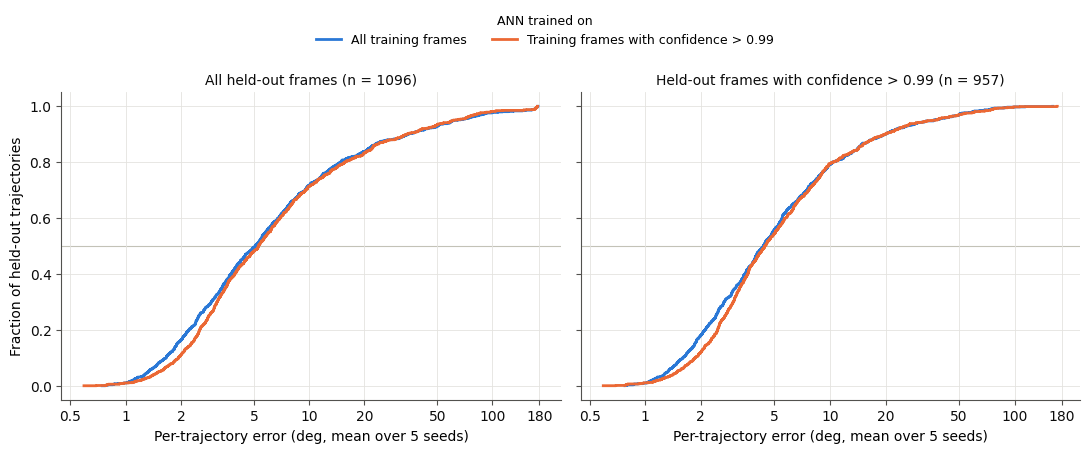

,eval set,ANN trained on,median,Q75,Q90,% > 15°,% > 90°
0,All held-out frames,All training frames,5.08,11.69,34.56,19.62,2.74
1,All held-out frames,Training frames with confidence > 0.99,5.30,11.98,33.86,20.80,2.28
2,Held-out frames with confidence > 0.99,All training frames,4.36,8.70,19.89,13.17,0.42
3,Held-out frames with confidence > 0.99,Training frames with confidence > 0.99,4.44,8.86,19.75,13.90,0.52


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (eval_set, f) in zip(axes, EVAL_SETS.items()):
    for model in MODELS:
        v = np.sort(seed_mean_per_traj(f, model, 'overall').values)
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where='post', color=COLORS[model], lw=2, label=MODELS[model])
    ax.axhline(0.5, color='#c3c2b7', lw=0.8, zorder=0)
    ax.set_xscale('log'); log_ticks(ax, [0.5, 1, 2, 5, 10, 20, 50, 100, 180], axis='x')
    ax.set_xlabel('Per-trajectory error (deg, mean over 5 seeds)')
    ax.set_title(f'{eval_set} (n = {f["trajec_objid"].nunique()})', fontsize=10, color=INK)
    style(ax); ax.grid(axis='x', color='#e4e3df', lw=0.6)
axes[0].set_ylabel('Fraction of held-out trajectories')
fig.legend(*axes[0].get_legend_handles_labels(), title='ANN trained on', frameon=False, fontsize=9, title_fontsize=9,
           loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_distribution.pdf', bbox_inches='tight')
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

q = []
for eval_set, f in EVAL_SETS.items():
    for model in MODELS:
        v = seed_mean_per_traj(f, model, 'overall')
        q.append({'eval set': eval_set, 'ANN trained on': MODELS[model], 'median': v.median(), 'Q75': v.quantile(0.75),
                  'Q90': v.quantile(0.9), '% > 15°': 100 * (v > 15).mean(), '% > 90°': 100 * (v > 90).mean()})
display(pd.DataFrame(q).round(2))

## 3. Error vs. the heading confidence of the held-out frame

Frames of all held-out trajectories, binned by their own `heading_confidence`. Left: median frame error in each bin (the line is the mean over the five seeds, the band their range). Right: how many of the held-out frames fall in each bin. The two bins right of the dashed line are the confident frames. A low-confidence frame has a less certain ground-truth heading, so a large error there can be a wrong label as well as a wrong prediction.

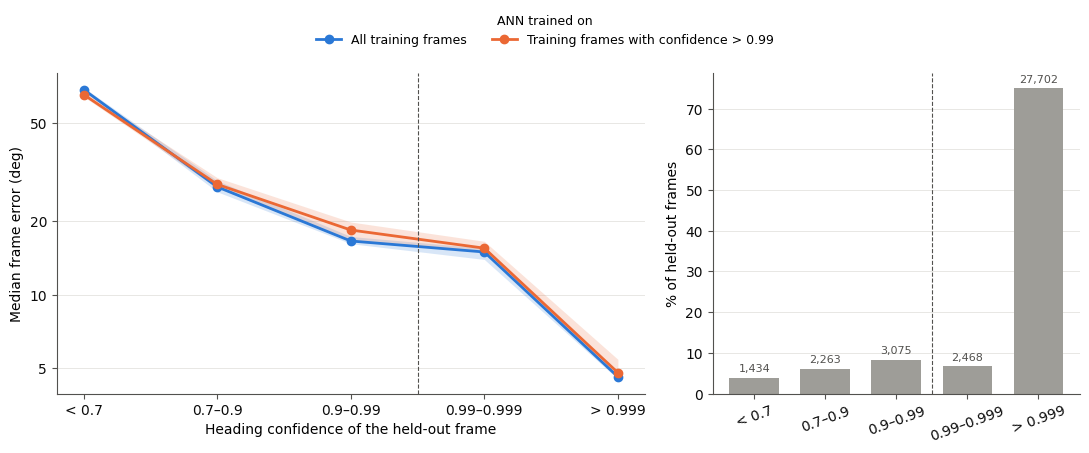

Median frame error (deg), mean over the five seeds


,frames,All training frames,Training frames with confidence > 0.99
conf_bin,,,
< 0.7,1434,68.55,65.41
0.7–0.9,2263,27.49,28.14
0.9–0.99,3075,16.53,18.33
0.99–0.999,2468,14.91,15.45
> 0.999,27702,4.62,4.80


In [4]:
EDGES = [0, 0.7, 0.9, 0.99, 0.999, 1.0]
LABELS = ['< 0.7', '0.7–0.9', '0.9–0.99', '0.99–0.999', '> 0.999']
frames['conf_bin'] = pd.cut(frames['heading_confidence'], EDGES, labels=LABELS, include_lowest=True)
x = np.arange(len(LABELS))

fig, (ax, ax_n) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
for model in MODELS:
    m = np.column_stack([frames.groupby('conf_bin', observed=False)[f'err_{model}_s{s}'].median().values for s in SEEDS])
    ax.fill_between(x, m.min(axis=1), m.max(axis=1), color=COLORS[model], alpha=0.18, lw=0)
    ax.plot(x, m.mean(axis=1), '-o', color=COLORS[model], lw=2, ms=6, label=MODELS[model])
ax.axvline(2.5, color=MUTED, lw=0.8, ls='--')
ax.set_xticks(x, LABELS); ax.set_xlabel('Heading confidence of the held-out frame')
ax.set_yscale('log'); log_ticks(ax, [2, 5, 10, 20, 50, 100])
ax.set_ylabel('Median frame error (deg)')
fig.legend(*ax.get_legend_handles_labels(), title='ANN trained on', frameon=False, fontsize=9, title_fontsize=9,
           loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
style(ax)

counts = frames['conf_bin'].value_counts().reindex(LABELS)
ax_n.bar(x, 100 * counts / counts.sum(), color='#9e9d98', width=0.7)
for xi, c in zip(x, counts):
    ax_n.text(xi, 100 * c / counts.sum() + 1, f'{c:,}', ha='center', va='bottom', fontsize=8, color=MUTED)
ax_n.axvline(2.5, color=MUTED, lw=0.8, ls='--')
ax_n.set_xticks(x, LABELS, rotation=20); ax_n.set_ylabel('% of held-out frames')
style(ax_n)
fig.tight_layout()
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_vs_confidence.pdf', bbox_inches='tight')
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_error_vs_confidence.png', dpi=300, bbox_inches='tight')
plt.show()

bins = pd.DataFrame({MODELS[m]: frames.groupby('conf_bin', observed=False)[[f'err_{m}_s{s}' for s in SEEDS]].median().mean(axis=1)
                     for m in MODELS})
bins.insert(0, 'frames', counts)
print('Median frame error (deg), mean over the five seeds')
display(bins.round(2))

## 4. Paired difference per trajectory

For every held-out trajectory, its error under each recipe (median over its frames, averaged over the five seeds), and the difference *full-data error − high-confidence error*: **positive means the high-confidence model is better** on that trajectory. Shown is the median difference with a 95% bootstrap CI over trajectories; the table adds the fraction of trajectories on which the high-confidence model is better and a Wilcoxon signed-rank test.

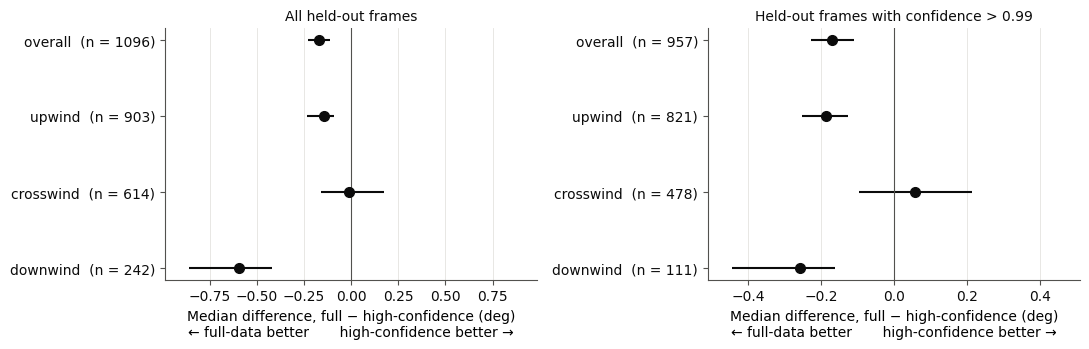

,eval set,regime,n,full-data median,high-confidence median,median diff (full − conf) [95% CI],% high-confidence better,Wilcoxon p
0,All held-out frames,overall,1096,5.08,5.30,"-0.17 [-0.23, -0.11]",40.24,1.5e-07
1,All held-out frames,upwind,903,5.03,5.24,"-0.15 [-0.24, -0.09]",42.19,9.6e-06
2,All held-out frames,crosswind,614,20.09,19.46,"-0.01 [-0.16, 0.18]",49.84,2.5e-01
3,All held-out frames,downwind,242,5.44,6.50,"-0.59 [-0.86, -0.42]",27.27,2.3e-12
4,Held-out frames with confidence > 0.99,overall,957,4.36,4.44,"-0.17 [-0.23, -0.11]",40.33,2.0e-08
5,Held-out frames with confidence > 0.99,upwind,821,4.26,4.41,"-0.19 [-0.25, -0.13]",39.59,4.1e-12
6,Held-out frames with confidence > 0.99,crosswind,478,11.79,12.40,"0.06 [-0.09, 0.21]",51.67,1.8e-01
7,Held-out frames with confidence > 0.99,downwind,111,3.49,3.59,"-0.26 [-0.44, -0.16]",32.43,2.8e-04


In [5]:
rows = []
for eval_set, f in EVAL_SETS.items():
    for group in GROUPS:
        a, b = seed_mean_per_traj(f, 'full', group), seed_mean_per_traj(f, 'conf', group)
        d = (a - b).values
        m, lo, hi = bootstrap_ci(d)
        rows.append({'eval set': eval_set, 'regime': group, 'n': len(d), 'full-data median': a.median(),
                     'high-confidence median': b.median(), 'median diff (full − conf)': m, 'ci95_lo': lo, 'ci95_hi': hi,
                     '% high-confidence better': 100 * (d > 0).mean(), 'Wilcoxon p': wilcoxon(d).pvalue})
paired = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))   # not sharey: each panel labels its own trajectory counts
for ax, eval_set in zip(axes, EVAL_SETS):
    p = paired[paired['eval set'] == eval_set].reset_index(drop=True)
    y = np.arange(len(p))[::-1]
    ax.errorbar(p['median diff (full − conf)'], y, xerr=[p['median diff (full − conf)'] - p['ci95_lo'], p['ci95_hi'] - p['median diff (full − conf)']],
                fmt='o', color=INK, ms=7, lw=1.5, capsize=0)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_yticks(y, [f'{r}  (n = {n})' for r, n in zip(p['regime'], p['n'])])
    ax.set_xlabel('Median difference, full − high-confidence (deg)\n← full-data better       high-confidence better →')
    ax.set_title(eval_set, fontsize=10, color=INK)
    style(ax); ax.grid(axis='y', visible=False); ax.grid(axis='x', color='#e4e3df', lw=0.6)
    lim = max(abs(p['ci95_lo']).max(), abs(p['ci95_hi']).max()) * 1.15
    ax.set_xlim(-lim, lim)
fig.tight_layout()
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_paired_difference.pdf', bbox_inches='tight')
fig.savefig(f'../figures/ann_conf{CONF_THRESHOLD}_paired_difference.png', dpi=300, bbox_inches='tight')
plt.show()

out = paired.copy()
out['median diff (full − conf) [95% CI]'] = out.apply(lambda r: f"{r['median diff (full − conf)']:.2f} [{r['ci95_lo']:.2f}, {r['ci95_hi']:.2f}]", axis=1)
out = out[['eval set', 'regime', 'n', 'full-data median', 'high-confidence median', 'median diff (full − conf) [95% CI]',
           '% high-confidence better', 'Wilcoxon p']]
out['Wilcoxon p'] = out['Wilcoxon p'].map('{:.1e}'.format)
display(out.round(2))

### Reading the results

(Numbers from the run of 21 October 2026; they change if either set of models is retrained.)

- **Leaving out the low-confidence frames does not improve the ANN.** Pooled over seeds, the high-confidence model is slightly *worse*: median per-trajectory error 5.28 ± 0.38° vs. 5.00 ± 0.05° on all held-out frames, and 4.46 ± 0.43° vs. 4.34 ± 0.10° on the confident held-out frames (Section 1). Per trajectory, the full-data model is better by a median 0.17° [0.11, 0.23] on both sets of frames, and the high-confidence model is better on only about 40 % of trajectories (Section 4).
- **This holds on the confident frames too**, where the ground truth is most reliable: removing 180° label errors from the training set did not buy accuracy on correctly labelled test frames.
- **Downwind is where the difference is largest** (full-data better by 0.59° [0.42, 0.86] on all frames, 0.26° [0.16, 0.44] on confident frames). It is also the regime the filter thins most: only 45 % of downwind training frames pass it, against 92 % of upwind frames (notebook 06). Crosswind shows no difference.
- **The high-confidence models are less stable**: their spread over seeds is several times that of the full-data models (sd 0.38° vs. 0.05° overall). The seed-42 high-confidence model happens to be its best (4.94°), which is why a comparison of the two seed-42 models alone would favour it.
- **The tails barely differ** (Section 2): on all frames 2.3 % (high-confidence) vs. 2.7 % (full-data) of trajectories have a median error above 90°, but slightly more exceed 15° (20.8 % vs. 19.6 %).
- **Both models fail on the same frames** (Section 3): frame error rises steeply as the held-out frame's own heading confidence falls, from a median of ~4.7° above 0.999 to ~67° below 0.7, almost identically for the two models. These frames' labels are themselves uncertain (the hand labels put the Viterbi error at ~27 % below 0.7), so part of this error is in the ground truth rather than the prediction. Note also that the 0.99–0.999 bin already has a median frame error of ~15°, three times that of the frames above 0.999.

The comparison uses the architecture selected for the full training set; it was not re-tuned for the smaller one.